# Customer Churn Prediction Using Machine Learning
**Course:** Artificial Intelligence — University of Lahore, Faculty of Information Technology  
**Dataset:** Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn`)  
**Goal:** Predict whether a telecom customer will leave the company (`Churn = Yes`) or stay (`Churn = No`).

**Pipeline:** 1) Load & understand → 2) Preprocess → 3) EDA → 4) Feature engineering & encoding → 5) Train/test split & training → 6) Evaluation → 7) Prediction on new customers.

## Step 1 — Data Loading and Understanding
We load the dataset with Pandas. The assignment names an Excel file (`.xlsx`); the copy provided is a `.csv`. The code below
loads whichever one exists, so it works with both.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score)
import joblib

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

In [2]:
# Load the dataset (Excel if available, otherwise CSV)
if os.path.exists("WA_Fn-UseC_-Telco-Customer-Churn.xlsx"):
    df = pd.read_excel("WA_Fn-UseC_-Telco-Customer-Churn.xlsx")
else:
    df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [3]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(list(df.columns))

Shape (rows, columns): (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [4]:
print("Data types:")
df.dtypes

Data types:


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
# Basic statistics - numeric columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
# Basic statistics - text (categorical) columns
df.describe(include="object").T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [8]:
# The target variable
print("Target variable: Churn")
print(df["Churn"].value_counts())
print("\nPercentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Target variable: Churn
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### What the important columns mean (in simple words)

| Column | Meaning |
|---|---|
| `customerID` | Unique ID of the customer. Just a label — has no predictive value. |
| `gender` | Male or Female. |
| `SeniorCitizen` | 1 if the customer is 65+ years old, otherwise 0. |
| `Partner` / `Dependents` | Whether the customer has a spouse/partner, or children/dependents. |
| `tenure` | Number of **months** the customer has stayed with the company. |
| `PhoneService` / `MultipleLines` | Whether they have phone service, and more than one line. |
| `InternetService` | Type of internet: DSL, Fiber optic, or No. |
| `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport` | Extra paid add-on services (Yes/No). |
| `StreamingTV`, `StreamingMovies` | Whether the customer streams TV / movies through the company. |
| `Contract` | Contract type: Month-to-month, One year, or Two year. |
| `PaperlessBilling` | Whether the customer receives bills electronically. |
| `PaymentMethod` | How the customer pays (electronic check, mailed check, bank transfer, credit card). |
| `MonthlyCharges` | Amount charged to the customer each month. |
| `TotalCharges` | Total amount charged over the whole time with the company. |
| **`Churn`** | **TARGET:** Did the customer leave in the last month? (Yes / No). |

## Step 2 — Data Preprocessing
Real data is messy. Before training a model we check for: missing values, duplicates, wrong data types,
useless columns, and inconsistent labels.

In [9]:
# 2.1 Missing values (NaN)
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing:", df.isnull().sum().sum())

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing: 0


No `NaN` values are reported — but `TotalCharges` is stored as `object` (text), although it should be a number.
That usually means some cells contain hidden blank strings (`" "`). Let's investigate.

In [10]:
# 2.2 Incorrect data type: TotalCharges
print("TotalCharges dtype:", df["TotalCharges"].dtype)
blank_mask = df["TotalCharges"].str.strip() == ""
print("Rows where TotalCharges is blank:", blank_mask.sum())
df[blank_mask][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

TotalCharges dtype: str
Rows where TotalCharges is blank: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


These 11 customers all have `tenure = 0` — they are brand-new customers who have not been billed yet, so `TotalCharges` is blank.
**Decision:** convert `TotalCharges` to numeric (blanks become `NaN`) and **drop these 11 rows**. They are only 0.16% of the data,
have no billing history, and none have churned, so removing them is safe and avoids guessing values.

In [11]:
# Convert to numeric; errors="coerce" turns the blanks into NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges after conversion:", df["TotalCharges"].isnull().sum())

# Drop those rows
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
print("New shape:", df.shape)
print("TotalCharges dtype now:", df["TotalCharges"].dtype)

Missing TotalCharges after conversion: 11
New shape: (7032, 21)
TotalCharges dtype now: float64


In [12]:
# 2.3 Duplicate records
print("Duplicate rows (full row):", df.duplicated().sum())
print("Duplicate customerIDs   :", df["customerID"].duplicated().sum())

Duplicate rows (full row): 0
Duplicate customerIDs   : 0


In [13]:
# 2.4 Unnecessary column: customerID is a unique label, it carries no pattern the model can learn
df = df.drop(columns=["customerID"])
print("Columns left:", df.shape[1])

Columns left: 20


In [14]:
# 2.5 SeniorCitizen is stored as 0/1 while all other Yes/No columns use text.
# Make it consistent so every Yes/No column is handled the same way.
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# 2.6 Inconsistent labels: "No internet service" and "No phone service" really mean "No".
# (The internet/phone status is already stored in InternetService / PhoneService.)
cols_no_internet = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                    "TechSupport", "StreamingTV", "StreamingMovies"]
for c in cols_no_internet:
    df[c] = df[c].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

# Check categorical columns for odd values
for c in df.select_dtypes(include="object").columns:
    print(f"{c:18s}", df[c].unique())

gender             <StringArray>
['Female', 'Male']
Length: 2, dtype: str
SeniorCitizen      <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Partner            <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents         <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService       <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines      <StringArray>
['No', 'Yes']
Length: 2, dtype: str
InternetService    <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity     <StringArray>
['No', 'Yes']
Length: 2, dtype: str
OnlineBackup       <StringArray>
['Yes', 'No']
Length: 2, dtype: str
DeviceProtection   <StringArray>
['No', 'Yes']
Length: 2, dtype: str
TechSupport        <StringArray>
['No', 'Yes']
Length: 2, dtype: str
StreamingTV        <StringArray>
['No', 'Yes']
Length: 2, dtype: str
StreamingMovies    <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Contract           <StringArray>
['Month-to-month', 'One year', 'Two year']
Length:

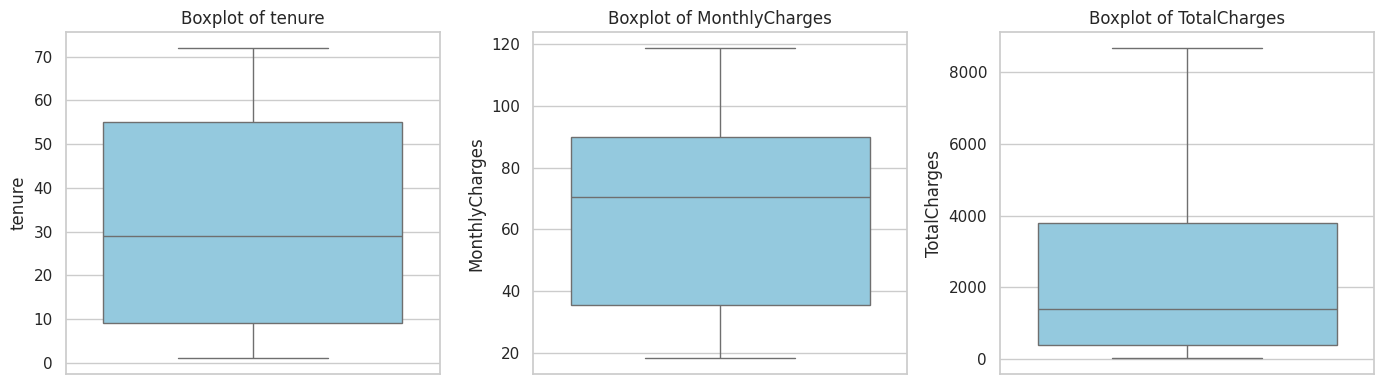

In [15]:
# 2.7 Check for outliers in numeric columns (boxplots)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

The boxplots show no extreme or impossible values (no negative charges, tenure between 1 and 72 months), so no outlier removal is needed.
The data is now clean.

In [16]:
print("Clean dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
df.head()

Clean dataset shape: (7032, 20)
Remaining missing values: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 3 — Exploratory Data Analysis (EDA)
Here we look for patterns that explain why customers leave.

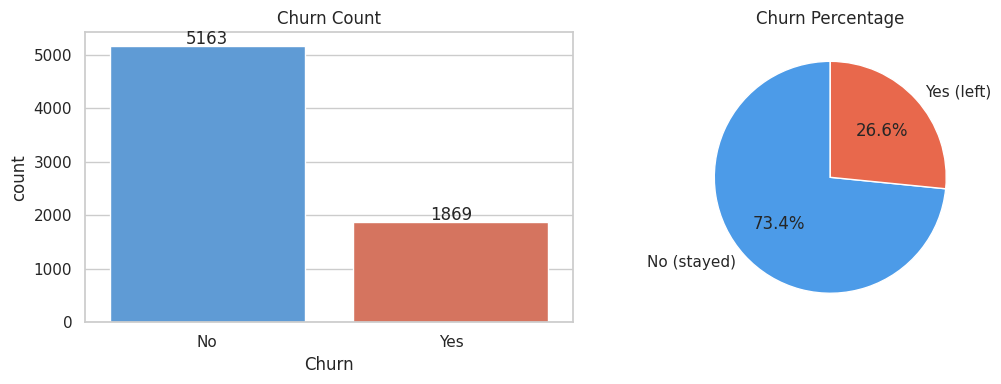

In [17]:
# 3.1 Churn distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = df["Churn"].value_counts()
sns.countplot(data=df, x="Churn", palette=["#4C9BE8", "#E8684C"], ax=axes[0])
axes[0].set_title("Churn Count")
for i, v in enumerate(counts[["No", "Yes"]]):
    axes[0].text(i, v + 40, str(v), ha="center")
axes[1].pie(counts[["No", "Yes"]], labels=["No (stayed)", "Yes (left)"], autopct="%1.1f%%",
            colors=["#4C9BE8", "#E8684C"], startangle=90)
axes[1].set_title("Churn Percentage")
plt.tight_layout(); plt.show()

**Observation:** The dataset is *imbalanced* — about 73% of customers stayed and 27% left. This matters later:
a model that always says "No Churn" would get ~73% accuracy while being useless. So we must look at Precision, Recall and F1, not only Accuracy.

In [18]:
# 3.2 Churn rate by categorical features (helper table + plots)
def churn_rate(col):
    t = (df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
           .round(2).sort_values(ascending=False).rename("Churn rate (%)"))
    return t.to_frame()

churn_rate("Contract")

,Churn rate (%)
Contract,
Month-to-month,42.71
One year,11.28
Two year,2.85


In [19]:
churn_rate("InternetService")

,Churn rate (%)
InternetService,
Fiber optic,41.89
DSL,19.00
No,7.43


In [20]:
churn_rate("PaymentMethod")

,Churn rate (%)
PaymentMethod,
Electronic check,45.29
Mailed check,19.20
Bank transfer (automatic),16.73
Credit card (automatic),15.25


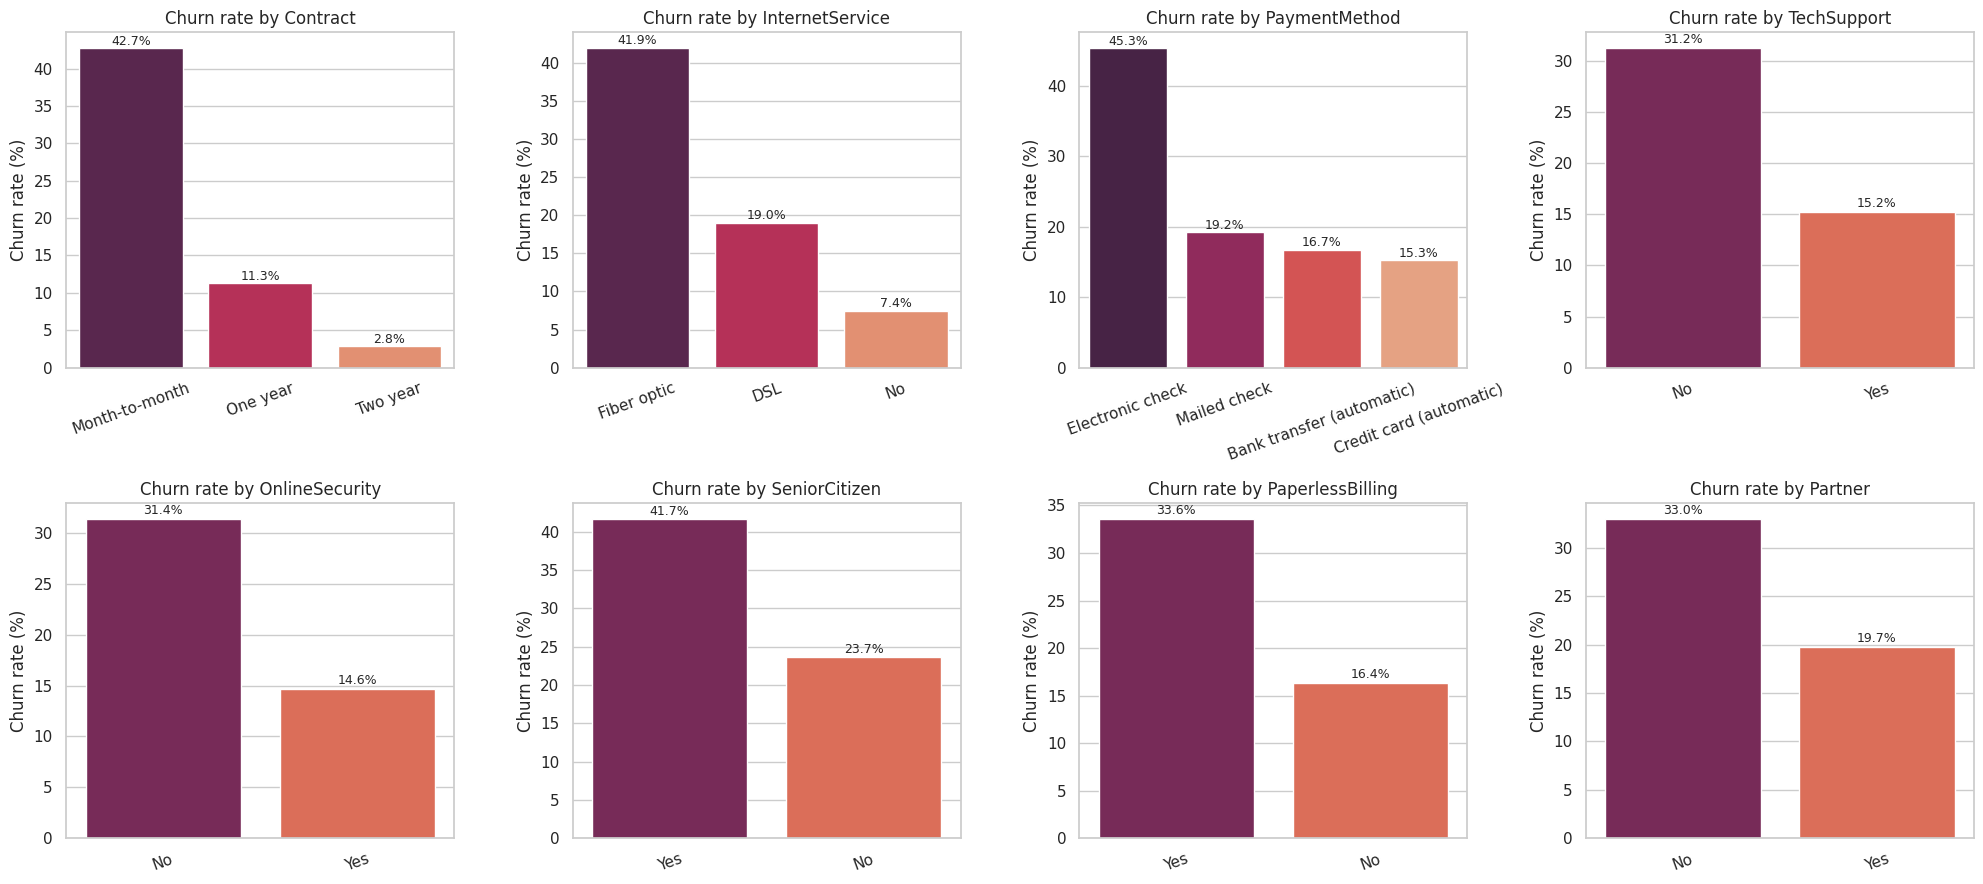

In [21]:
cat_plot = ["Contract", "InternetService", "PaymentMethod", "TechSupport",
            "OnlineSecurity", "SeniorCitizen", "PaperlessBilling", "Partner"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), cat_plot):
    rate = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, palette="rocket")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

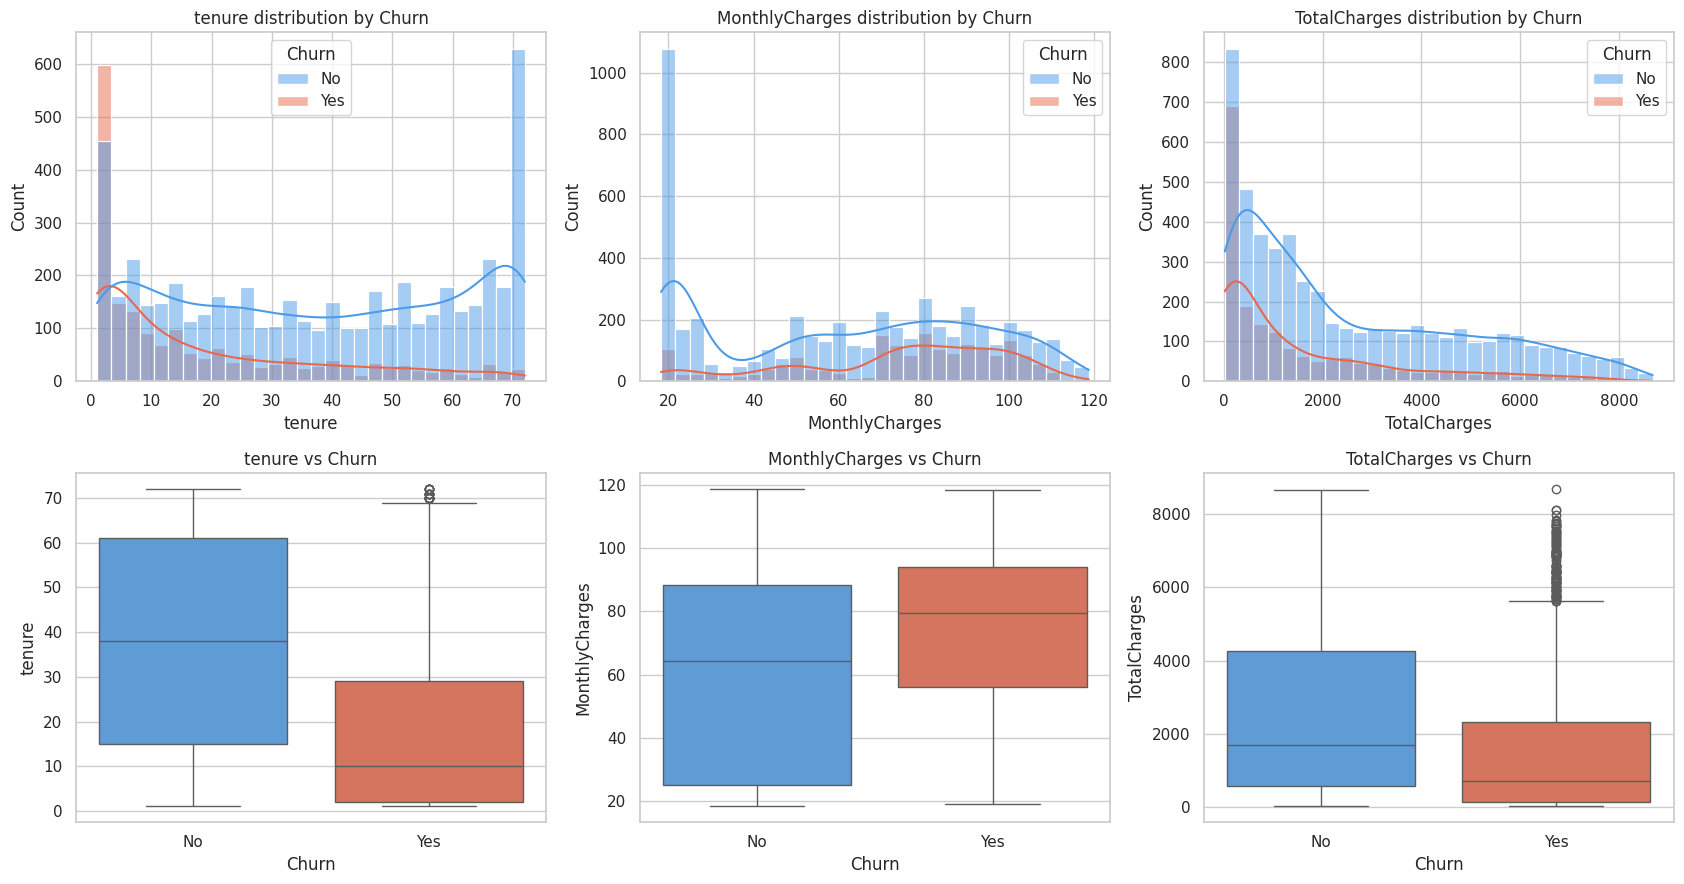

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.65,61.31,2555.34
Yes,17.98,74.44,1531.80


In [22]:
# 3.3 Numeric features vs churn
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for i, col in enumerate(["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, bins=30, ax=axes[0, i],
                 palette={"No": "#4C9BE8", "Yes": "#E8684C"})
    axes[0, i].set_title(f"{col} distribution by Churn")
    sns.boxplot(data=df, x="Churn", y=col, ax=axes[1, i], palette={"No": "#4C9BE8", "Yes": "#E8684C"})
    axes[1, i].set_title(f"{col} vs Churn")
plt.tight_layout(); plt.show()

df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(2)

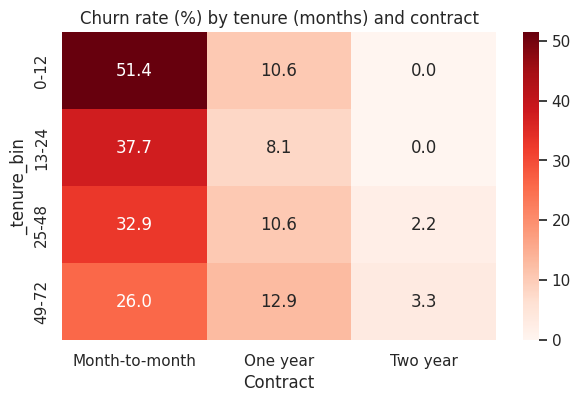

In [23]:
# 3.4 Churn by contract AND tenure together
df["_tenure_bin"] = pd.cut(df["tenure"], bins=[0, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
pivot = df.pivot_table(index="_tenure_bin", columns="Contract", values="Churn",
                       aggfunc=lambda s: (s == "Yes").mean() * 100).round(1)
plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn rate (%) by tenure (months) and contract")
plt.show()
df = df.drop(columns="_tenure_bin")

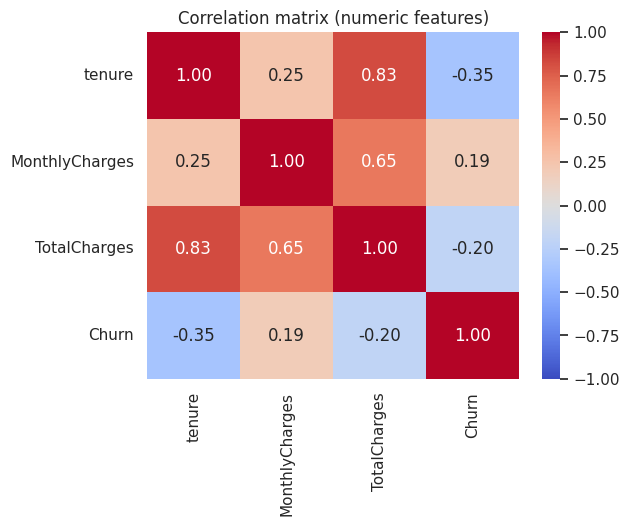

In [24]:
# 3.5 Correlation of numeric features (with Churn as 0/1)
tmp = df[["tenure", "MonthlyCharges", "TotalCharges"]].copy()
tmp["Churn"] = (df["Churn"] == "Yes").astype(int)
plt.figure(figsize=(6, 4.5))
sns.heatmap(tmp.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix (numeric features)")
plt.show()

### Key EDA findings
1. **Contract type is the strongest signal.** Month-to-month customers churn at ~43%, one-year ~11%, two-year only ~3%.
2. **New customers leave most.** Churners have a much lower tenure (average ≈ 18 months vs ≈ 38 for loyal customers). The first year is the riskiest.
3. **Fiber optic internet users churn more (~42%)** than DSL (~19%) or no-internet customers (~7%) — possibly due to price or service quality.
4. **Higher monthly charges → more churn.** Churners pay about $74/month on average vs about $61 for those who stay.
5. **Add-on support services help retention.** Customers who have Tech Support or Online Security churn at roughly half the rate (or less) of those who do not.
6. **Electronic check payers** churn the most (~45%); customers on automatic payment methods churn the least.
7. `tenure` and `TotalCharges` are strongly correlated (≈ 0.83) — expected, since total = months × monthly price.

## Step 4 — Feature Engineering and Encoding
Machine-learning models only understand numbers, so text categories must be converted. We also create a few new features that capture
useful ideas more directly.

### 4.1 New features
- **`NumServices`** — how many add-on services the customer uses (0–8). More services usually means a more "locked-in" customer.
- **`AvgMonthlySpend`** — `TotalCharges / tenure`: real average spend per month.
- **`TenureGroup`** — tenure bucketed into stages of the customer lifecycle (0–1y, 1–2y, 2–4y, 4–6y).

In [25]:
df_fe = df.copy()

service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
# count of services (InternetService != "No" also counts as a service)
df_fe["NumServices"] = (df_fe[service_cols] == "Yes").sum(axis=1) + (df_fe["InternetService"] != "No").astype(int)

df_fe["AvgMonthlySpend"] = (df_fe["TotalCharges"] / df_fe["tenure"]).round(2)

df_fe["TenureGroup"] = pd.cut(df_fe["tenure"], bins=[0, 12, 24, 48, 72],
                              labels=["0-1yr", "1-2yr", "2-4yr", "4-6yr"]).astype(str)

df_fe[["tenure", "TenureGroup", "NumServices", "MonthlyCharges", "TotalCharges", "AvgMonthlySpend"]].head()

,tenure,TenureGroup,NumServices,MonthlyCharges,TotalCharges,AvgMonthlySpend
0,1,0-1yr,2,29.85,29.85,29.85
1,34,2-4yr,4,56.95,1889.50,55.57
2,2,0-1yr,4,53.85,108.15,54.08
3,45,2-4yr,4,42.30,1840.75,40.91
4,2,0-1yr,2,70.70,151.65,75.82


### 4.2 Encoding categorical variables
We use two techniques:
- **Binary (Label) encoding** for Yes/No-type columns and gender → `Yes=1`, `No=0`. (Only two values, so one 0/1 column is enough.)
- **One-Hot encoding** for columns with 3+ unrelated categories (`InternetService`, `Contract`, `PaymentMethod`, `TenureGroup`).
  Using 0/1 columns avoids telling the model that, e.g., "Two year" is "bigger" than "Fiber optic". We use `drop_first=True` to avoid redundant columns.
- The **target** `Churn` is encoded as Yes=1, No=0.

In [26]:
binary_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
               "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
               "StreamingTV", "StreamingMovies", "PaperlessBilling"]

for c in binary_cols:
    if c == "gender":
        df_fe[c] = df_fe[c].map({"Female": 0, "Male": 1})
    else:
        df_fe[c] = df_fe[c].map({"No": 0, "Yes": 1})

# Target
df_fe["Churn"] = df_fe["Churn"].map({"No": 0, "Yes": 1})

# One-hot encoding for multi-category columns
multi_cols = ["InternetService", "Contract", "PaymentMethod", "TenureGroup"]
df_enc = pd.get_dummies(df_fe, columns=multi_cols, drop_first=True, dtype=int)

print("Shape after encoding:", df_enc.shape)
df_enc.head()

Shape after encoding: (7032, 29)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,NumServices,AvgMonthlySpend,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_1-2yr,TenureGroup_2-4yr,TenureGroup_4-6yr
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,2,29.85,0,0,0,0,0,1,0,0,0,0
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,4,55.57,0,0,1,0,0,0,1,0,1,0
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,4,54.08,0,0,0,0,0,0,1,0,0,0
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,4,40.91,0,0,1,0,0,0,0,0,1,0
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,2,75.82,1,0,0,0,0,1,0,0,0,0


In [27]:
# 4.3 Separate input features (X) from the target (y)
X = df_enc.drop(columns="Churn")
y = df_enc["Churn"]

print("X shape:", X.shape, "| y shape:", y.shape)
print("\nFeature columns used by the model:")
print(list(X.columns))
print("\nAny non-numeric columns left in X? ->", (X.dtypes == "object").any())

X shape: (7032, 28) | y shape: (7032,)

Feature columns used by the model:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'NumServices', 'AvgMonthlySpend', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'TenureGroup_1-2yr', 'TenureGroup_2-4yr', 'TenureGroup_4-6yr']

Any non-numeric columns left in X? -> False


## Step 5 — Training and Testing
### 5.1 Train/test split
We keep **80% for training** and **20% for testing** (data the model has never seen — this tells us how it will behave on real new customers).
`stratify=y` keeps the same churn ratio (~27%) in both sets, which matters because the data is imbalanced.
`random_state=42` makes the split reproducible.

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate in train: %.2f%%" % (y_train.mean() * 100))
print("Churn rate in test : %.2f%%" % (y_test.mean() * 100))

Train: (5625, 28)  Test: (1407, 28)
Churn rate in train: 26.58%
Churn rate in test : 26.58%


### 5.2 Feature scaling (for Logistic Regression only)
`tenure`, `MonthlyCharges`, `TotalCharges` have very different ranges. Logistic Regression is sensitive to scale, so we standardise them
(mean 0, std 1). The scaler is **fit on training data only** to avoid *data leakage*. Tree-based models don't need scaling.

In [29]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlySpend", "NumServices"]

scaler = StandardScaler()
X_train_sc = X_train.copy()
X_test_sc = X_test.copy()
X_train_sc[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit on train only
X_test_sc[num_cols]  = scaler.transform(X_test[num_cols])        # only transform test

X_train_sc[num_cols].describe().round(2).loc[["mean", "std"]]

,tenure,MonthlyCharges,TotalCharges,AvgMonthlySpend,NumServices
mean,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


### 5.3 Train three classification models
1. **Logistic Regression** — simple, fast, interpretable baseline.
2. **Decision Tree** — rule-based (if/else) model; `max_depth=5` stops it from memorising the training data (overfitting).
3. **Random Forest** — many decision trees voting together; usually more accurate and stable.

Because only ~27% of customers churn, we use `class_weight="balanced"`: mistakes on the rare "churn" class are penalised more,
so the model pays proper attention to churners (improves Recall).

In [30]:
lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)

lr.fit(X_train_sc, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)
print("All three models trained successfully.")

All three models trained successfully.


## Step 6 — Model Evaluation
Metrics (with "churn" as the positive class):
- **Accuracy** — % of all predictions that were correct.
- **Precision** — of customers predicted to churn, how many really did? (avoids wasting retention offers)
- **Recall** — of customers who really churned, how many did we catch? (avoids missing leaving customers)
- **F1-Score** — balance of Precision and Recall.
- **Confusion Matrix** — table of correct/incorrect predictions (TN, FP, FN, TP).
- **ROC-AUC** — how well the model separates churners from non-churners (1.0 = perfect, 0.5 = random).

In [31]:
models = {
    "Logistic Regression": (lr, X_test_sc),
    "Decision Tree":       (dt, X_test),
    "Random Forest":       (rf, X_test),
}

rows, preds, probas = [], {}, {}
for name, (m, Xt) in models.items():
    p = m.predict(Xt)
    pr = m.predict_proba(Xt)[:, 1]
    preds[name], probas[name] = p, pr
    rows.append({"Model": name,
                 "Accuracy":  accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall":    recall_score(y_test, p),
                 "F1-Score":  f1_score(y_test, p),
                 "ROC-AUC":   roc_auc_score(y_test, pr)})

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7228,0.4868,0.7888,0.6020,0.8344
Decision Tree,0.7008,0.4630,0.7861,0.5828,0.8178
Random Forest,0.7512,0.5213,0.7861,0.6269,0.8405


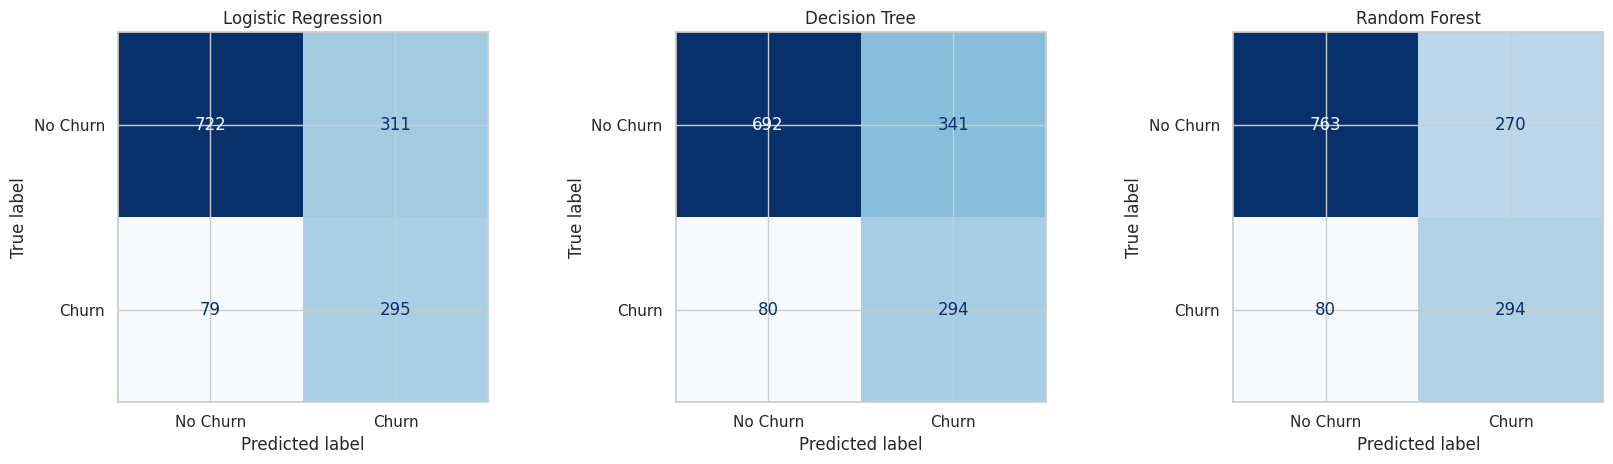

In [32]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["No Churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [33]:
# Detailed report for each model
for name in models:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    print("=" * 60)
    print(name, f"-> TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    print(classification_report(y_test, preds[name], target_names=["No Churn", "Churn"]))

Logistic Regression -> TN=722, FP=311, FN=79, TP=295
              precision    recall  f1-score   support

    No Churn       0.90      0.70      0.79      1033
       Churn       0.49      0.79      0.60       374

    accuracy                           0.72      1407
   macro avg       0.69      0.74      0.69      1407
weighted avg       0.79      0.72      0.74      1407

Decision Tree -> TN=692, FP=341, FN=80, TP=294
              precision    recall  f1-score   support

    No Churn       0.90      0.67      0.77      1033
       Churn       0.46      0.79      0.58       374

    accuracy                           0.70      1407
   macro avg       0.68      0.73      0.67      1407
weighted avg       0.78      0.70      0.72      1407

Random Forest -> TN=763, FP=270, FN=80, TP=294
              precision    recall  f1-score   support

    No Churn       0.91      0.74      0.81      1033
       Churn       0.52      0.79      0.63       374

    accuracy                       

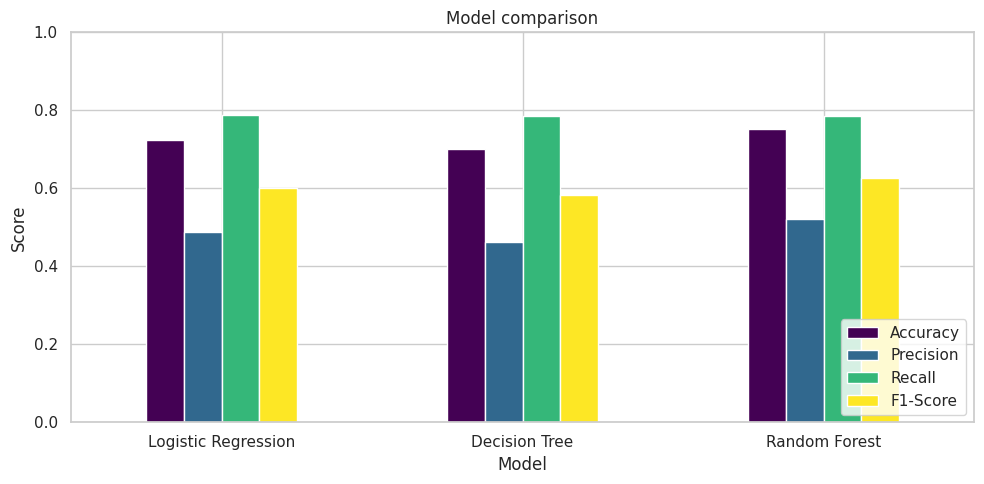

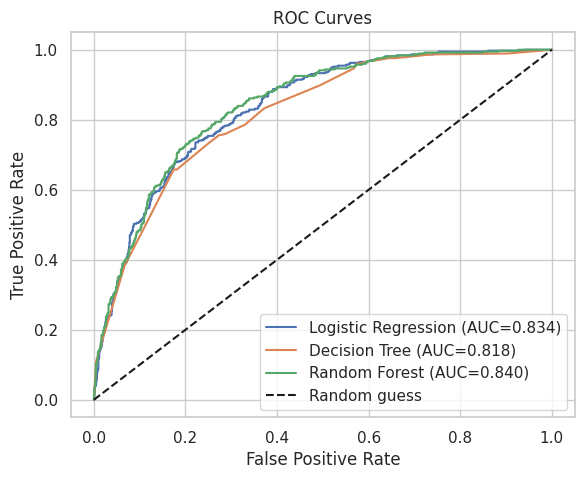

In [34]:
# Visual comparison of metrics
results.drop(columns="ROC-AUC").plot(kind="bar", figsize=(10, 5), colormap="viridis", rot=0)
plt.title("Model comparison"); plt.ylabel("Score"); plt.ylim(0, 1); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

# ROC curves
plt.figure(figsize=(6.5, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probas[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curves"); plt.legend()
plt.show()

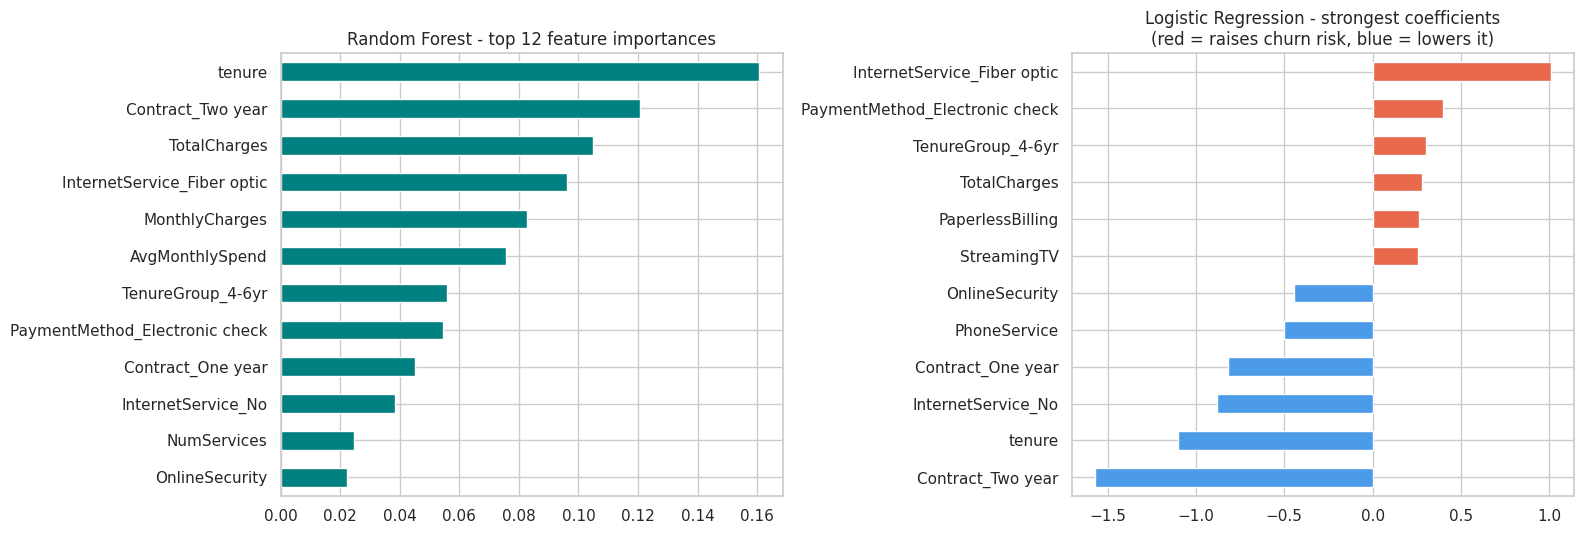

In [35]:
# Which features drive the predictions? (Random Forest importance + Logistic Regression coefficients)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True).tail(12)
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values()
coef_top = pd.concat([coef.head(6), coef.tail(6)])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
imp.plot(kind="barh", ax=axes[0], color="teal"); axes[0].set_title("Random Forest - top 12 feature importances")
coef_top.plot(kind="barh", ax=axes[1], color=["#4C9BE8" if v < 0 else "#E8684C" for v in coef_top])
axes[1].set_title("Logistic Regression - strongest coefficients\n(red = raises churn risk, blue = lowers it)")
plt.tight_layout(); plt.show()

In [36]:
# Check for overfitting: compare train vs test F1
for name, (m, Xt) in models.items():
    Xtr = X_train_sc if name == "Logistic Regression" else X_train
    print(f"{name:20s} train F1 = {f1_score(y_train, m.predict(Xtr)):.3f} | test F1 = {f1_score(y_test, m.predict(Xt)):.3f}")

Logistic Regression  train F1 = 0.636 | test F1 = 0.602
Decision Tree        train F1 = 0.626 | test F1 = 0.583


Random Forest        train F1 = 0.689 | test F1 = 0.627


In [37]:
best_name = results["F1-Score"].idxmax()
print("Best model by F1-Score:", best_name)
results.loc[best_name]

Best model by F1-Score: Random Forest


Accuracy     0.7512
Precision    0.5213
Recall       0.7861
F1-Score     0.6269
ROC-AUC      0.8405
Name: Random Forest, dtype: float64

### Which model is better, and why?

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.723 | 0.487 | 0.789 | 0.602 | 0.834 |
| Decision Tree | 0.701 | 0.463 | 0.786 | 0.583 | 0.818 |
| **Random Forest** | **0.751** | **0.521** | 0.786 | **0.627** | **0.841** |

* **Random Forest is the best model.** It has the highest Accuracy, Precision, F1-Score and ROC-AUC. All three models catch about the same share of churners (Recall ≈ 79%), so the difference is in **Precision**: Random Forest raises fewer false alarms (270 wrongly flagged customers vs 311 for Logistic Regression and 341 for the Decision Tree).
* **Why Random Forest wins:** it combines 300 different trees, which reduces the errors and over-fitting of a single tree, and it can capture non-linear relationships and feature interactions (e.g. *short tenure AND month-to-month AND fiber*) that Logistic Regression cannot.
* **Decision Tree is the weakest** because one shallow tree is a rough, unstable model.
* **Logistic Regression is a strong baseline** (AUC 0.834 — very close to Random Forest) and is easy to explain, so it is a good choice if interpretability matters most.
* **Accuracy looks lower than the 73% "always say No Churn" trick** — that is expected and intentional. Using `class_weight="balanced"` trades some accuracy for much higher Recall (79% of real churners caught instead of far fewer). For a retention team, missing a leaving customer is usually costlier than contacting a customer who would have stayed.
* **Overfitting check:** train F1 (0.69) vs test F1 (0.63) for Random Forest — a small gap, so the model generalises reasonably well.

## Step 7 — Application / Prediction
We now use the final model on **new customers**. A real user supplies raw information (e.g. "Month-to-month contract, 3 months tenure…").
The function below:
1. takes the customer's raw details as a Python dictionary,
2. applies the **same** feature engineering and encoding as training,
3. lines the columns up exactly with the training columns, scales numbers if needed,
4. returns **Churn / No Churn** and the churn probability.

In [38]:
final_model = {"Logistic Regression": lr, "Decision Tree": dt, "Random Forest": rf}[best_name]
uses_scaling = (best_name == "Logistic Regression")

def predict_churn(customer: dict, threshold: float = 0.5):
    """customer: raw details exactly like the original dataset (without customerID / Churn)."""
    c = pd.DataFrame([customer])

    # same feature engineering as training
    c["NumServices"] = (c[service_cols] == "Yes").sum(axis=1) + (c["InternetService"] != "No").astype(int)
    c["AvgMonthlySpend"] = (c["TotalCharges"] / c["tenure"]).round(2)
    c["TenureGroup"] = pd.cut(c["tenure"], bins=[0, 12, 24, 48, 72],
                              labels=["0-1yr", "1-2yr", "2-4yr", "4-6yr"]).astype(str)

    # same encoding as training
    for col in binary_cols:
        c[col] = c[col].map({"Female": 0, "Male": 1}) if col == "gender" else c[col].map({"No": 0, "Yes": 1})
    c = pd.get_dummies(c, columns=multi_cols, dtype=int)
    c = c.reindex(columns=X.columns, fill_value=0)      # match training columns exactly

    if uses_scaling:
        c[num_cols] = scaler.transform(c[num_cols])

    prob = final_model.predict_proba(c)[0, 1]
    label = "Churn" if prob >= threshold else "No Churn"
    return label, prob

In [39]:
# Three sample customers (raw input, like a row of the original dataset)
customers = {
 "Customer A (new, month-to-month, fiber, e-check)": dict(
    gender="Female", SeniorCitizen="No", Partner="No", Dependents="No", tenure=3,
    PhoneService="Yes", MultipleLines="No", InternetService="Fiber optic",
    OnlineSecurity="No", OnlineBackup="No", DeviceProtection="No", TechSupport="No",
    StreamingTV="Yes", StreamingMovies="Yes", Contract="Month-to-month", PaperlessBilling="Yes",
    PaymentMethod="Electronic check", MonthlyCharges=95.70, TotalCharges=287.10),

 "Customer B (loyal, 2-year contract, DSL, auto-pay)": dict(
    gender="Male", SeniorCitizen="No", Partner="Yes", Dependents="Yes", tenure=60,
    PhoneService="Yes", MultipleLines="Yes", InternetService="DSL",
    OnlineSecurity="Yes", OnlineBackup="Yes", DeviceProtection="Yes", TechSupport="Yes",
    StreamingTV="No", StreamingMovies="No", Contract="Two year", PaperlessBilling="No",
    PaymentMethod="Credit card (automatic)", MonthlyCharges=72.40, TotalCharges=4344.00),

 "Customer C (senior, 1-year contract, mixed profile)": dict(
    gender="Male", SeniorCitizen="Yes", Partner="No", Dependents="No", tenure=14,
    PhoneService="Yes", MultipleLines="No", InternetService="Fiber optic",
    OnlineSecurity="No", OnlineBackup="Yes", DeviceProtection="No", TechSupport="No",
    StreamingTV="No", StreamingMovies="No", Contract="One year", PaperlessBilling="Yes",
    PaymentMethod="Bank transfer (automatic)", MonthlyCharges=79.90, TotalCharges=1118.60),
}

print("Model used:", best_name, "\n")
for name, cust in customers.items():
    label, prob = predict_churn(cust)
    print(f"{name}\n   -> Prediction: {label}   (churn probability = {prob:.1%})\n")

Model used: Random Forest 

Customer A (new, month-to-month, fiber, e-check)
   -> Prediction: Churn   (churn probability = 90.2%)

Customer B (loyal, 2-year contract, DSL, auto-pay)
   -> Prediction: No Churn   (churn probability = 4.1%)

Customer C (senior, 1-year contract, mixed profile)
   -> Prediction: Churn   (churn probability = 54.3%)



In [40]:
# Predictions for 8 real customers from the test set, compared with what actually happened
sample = X_test.sample(8, random_state=7)
Xs = scaler.transform(sample[num_cols]) if uses_scaling else None
inp = sample.copy()
if uses_scaling:
    inp[num_cols] = Xs
p = final_model.predict_proba(inp)[:, 1]
out = pd.DataFrame({
    "Contract": df.loc[sample.index, "Contract"].values,
    "Tenure": sample["tenure"].values,
    "MonthlyCharges": sample["MonthlyCharges"].values,
    "Churn prob": p.round(3),
    "Predicted": np.where(p >= 0.5, "Churn", "No Churn"),
    "Actual": np.where(y_test.loc[sample.index].values == 1, "Churn", "No Churn"),
}, index=sample.index)
out

,Contract,Tenure,MonthlyCharges,Churn prob,Predicted,Actual
2228,Month-to-month,54,69.90,0.121,No Churn,No Churn
2580,Two year,37,19.80,0.027,No Churn,No Churn
653,Month-to-month,8,19.65,0.320,No Churn,Churn
6878,Month-to-month,3,89.85,0.826,Churn,No Churn
3858,Month-to-month,1,24.00,0.487,No Churn,No Churn
3281,Month-to-month,35,95.45,0.726,Churn,Churn
4600,Two year,55,77.80,0.065,No Churn,No Churn
3708,Two year,69,59.75,0.024,No Churn,No Churn


In [41]:
# Save the final model so it can be reused without retraining
joblib.dump({"model": final_model, "scaler": scaler, "columns": list(X.columns)}, "churn_model.joblib")
print("Saved: churn_model.joblib")

Saved: churn_model.joblib


## Conclusion

**Best model.** Random Forest gave the best overall performance on unseen data: Accuracy 75.1%, Precision 52.1%, Recall 78.6%, F1 0.627 and ROC-AUC 0.841.
It correctly identified 294 of the 374 customers in the test set who actually left.

**Important observations from the data.**
* About 26.5% of customers churn (an imbalanced dataset), so Accuracy alone is misleading.
* Churn is driven mostly by **contract type, tenure, internet service type, monthly price and payment method**. Short-contract, new, high-paying, fiber-optic, electronic-check customers are the highest risk; long-contract, long-tenure customers with support services are the safest.
* Gender had almost no influence on churn.

**Limitations.**
* Precision is only ~52%: about half of the customers flagged as "churn" would actually have stayed, so retention offers will sometimes go to the wrong people.
* The dataset is a single snapshot (one row per customer) — it does not show behaviour over time (e.g. complaints, call-centre contacts, usage drops) which would improve predictions.
* The data is limited to ~7,000 customers from one company and may not generalise to other markets or time periods.
* The model predicts *who* is at risk, not *why* a particular person will leave or *which offer* will keep them.
* We used default-style hyper-parameters with limited tuning; more tuning, or models such as Gradient Boosting, might perform slightly better. The decision threshold (0.5) can also be changed to favour Recall or Precision.

**How a telecom company can use this system.**
1. Score all customers every month and give the retention team a ranked list of the highest-risk customers.
2. Target these customers with offers: discounts, upgrading from month-to-month to a 1- or 2-year contract, bundling Tech Support / Online Security, or moving them from electronic check to automatic payment.
3. Pay special attention to new customers in their first year with an onboarding / welcome programme.
4. Measure the saved revenue against the cost of the offers and adjust the probability threshold to match the retention budget.
5. Re-train the model regularly with fresh data to keep it accurate.